# 00 · Foundations: data, losses, over-fitting and honest testing

*Level: beginner. Pairs with Part I of the learning guide (`docs/overleaf_ml_guide/ml_guide.tex`, Sections 1–4).*

Every later notebook builds on six ideas:

1. what one **training example** is in this project;
2. why we predict **logarithms**;
3. **learning = minimizing a loss**, done by **gradient descent**;
4. **over-fitting**: why the training error says little;
5. **honest testing**: split by packet, never by row;
6. the bit of **probability** needed for error bars.

We use the **toy CCD world** (`src/ml/synthetic.py`). It is a simulator that produces packets like the real ones: settings, trace features,
curves, and image labels with realistic noise. Its physics is invented, so it can be used to understand methods, not the real CCD.

In [1]:
from tutorial_utils import *

## 1. One example = one amplifier's traces in one packet

A synthetic scan of 60 packets. Each packet is read by 4 amplifiers, so there are 240 rows. Each row holds:
* `theta.*`: the settings (10 grouped parameters in the toy world);
* `trace.*` / `ref.*`: hand-made trace features at the settings and at the reference;
* `label.*`: the image's three labels.

The `truth.*` columns are the simulator's hidden truth. They are never inputs; we use them only to look behind the scenes.

In [2]:
df, curves, Y, groups = toy_scan(60, seed=1)
print(df.shape, "rows x columns;", df.packet_id.nunique(), "packets")
show = ["packet_id", "board", "channel", "theta.VDD", "theta.VSUB", data.columns(df, "trace")[11], "label.sigma_e", "label.lambda_e_per_bin", "label.gain_adu_per_e"]
df[show].head(8)

(240, 89) rows x columns; 60 packets


,packet_id,board,channel,theta.VDD,theta.VSUB,trace.skip: CDS rms (detrended),label.sigma_e,label.lambda_e_per_bin,label.gain_adu_per_e
0,syn_00000,100,0,-18.952714,37.883192,-0.421561,0.313358,0.089355,1.321801
1,syn_00000,100,1,-18.952714,37.883192,5.153211,0.316120,0.089117,1.284059
2,syn_00000,100,2,-18.952714,37.883192,65.031968,1.239071,0.093652,2.638342
3,syn_00000,100,3,-18.952714,37.883192,9.566112,0.316206,0.091658,1.278241
4,syn_00001,100,0,-17.985948,41.594634,-0.558893,0.287779,0.119496,1.342118
5,syn_00001,100,1,-17.985948,41.594634,5.357789,0.321281,0.114891,1.325005
6,syn_00001,100,2,-17.985948,41.594634,67.772932,1.286698,0.115345,2.696617
7,syn_00001,100,3,-17.985948,41.594634,9.667876,0.308372,0.117942,1.291854


## 2. Why logarithms

σe, λ and the gain are positive and vary by **factors** (one amplifier is ~4× noisier). In logs:

* an error is a **relative** error: $\log\hat y - \log y = \log(\hat y / y) \approx (\hat y - y)/y$;
* products become sums: $\log\sigma_e = \log\sigma_\text{ADU} - \log g$.

`Y` therefore holds $(\log\sigma_e, \log\lambda, \log g)$.

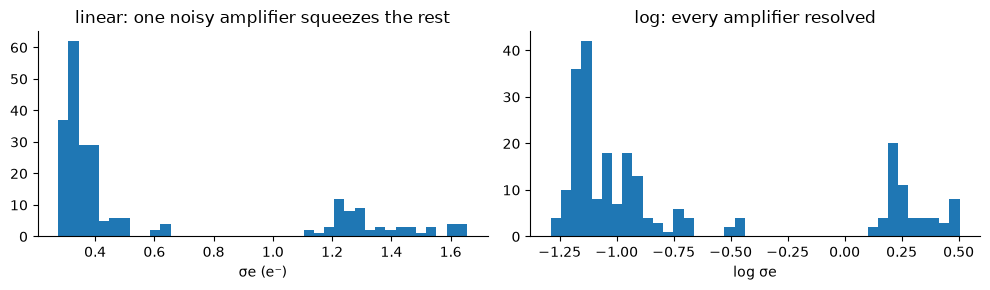

a 5 % over-prediction: log(1.05/1.00) = 0.0488  ≈ 0.05


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(df["label.sigma_e"], 40); ax[0].set_xlabel("σe (e⁻)"); ax[0].set_title("linear: one noisy amplifier squeezes the rest")
ax[1].hist(Y[:, 0], 40); ax[1].set_xlabel("log σe"); ax[1].set_title("log: every amplifier resolved")
plt.tight_layout(); plt.show()
yhat, y = 1.05, 1.00
print(f"a 5 % over-prediction: log(1.05/1.00) = {np.log(yhat / y):.4f}  ≈ 0.05")

## 3. Learning = minimizing a loss: gradient descent from scratch

The simplest model is a straight line, $f(x) = w_1 x + w_0$. Take as input $x$ the trace feature most correlated with $\log\sigma_e$ (standardized),
and as target $y = \log\sigma_e$. The **mean squared error**

$$L(w_0, w_1) = \frac1n\sum_i \bigl(y_i - w_1 x_i - w_0\bigr)^2$$

is minimized by **gradient descent**, $w \leftarrow w - \eta\,\nabla L$. Here
* $\eta$ is the learning rate;
* the gradient has two components: $\partial L/\partial w_1 = -\frac2n\sum_i x_i r_i$ and $\partial L/\partial w_0 = -\frac2n\sum_i r_i$, with residuals $r_i = y_i - f(x_i)$.

input: trace.skip: CDS rms (detrended)
gradient descent: w1 = 0.5755, w0 = -0.7082   |   exact: w1 = 0.5755, w0 = -0.7082


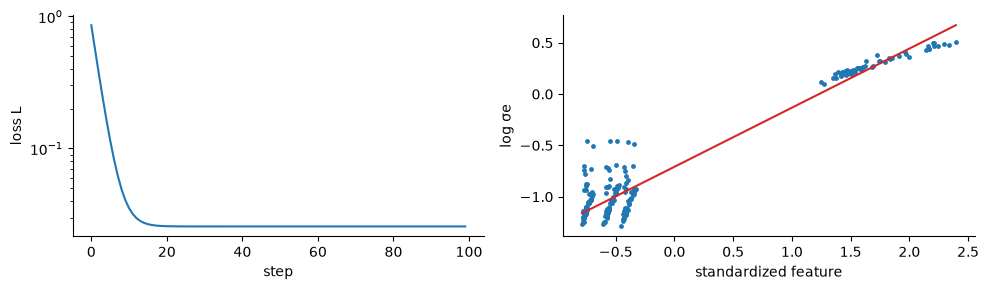

In [4]:
F = df[data.columns(df, "trace")].to_numpy(float)
best = int(np.argmax([abs(np.corrcoef(F[:, k], Y[:, 0])[0, 1]) for k in range(F.shape[1])]))
x = (F[:, best] - F[:, best].mean()) / F[:, best].std()
y = Y[:, 0]
print("input:", data.columns(df, "trace")[best])

w0, w1, eta, losses = 0.0, 0.0, 0.1, []
for step in range(100):
    r = y - (w1 * x + w0)                       # residuals
    losses.append(np.mean(r ** 2))
    g1, g0 = -2 * np.mean(x * r), -2 * np.mean(r)  # the gradient
    w1, w0 = w1 - eta * g1, w0 - eta * g0       # one step downhill
A = np.column_stack([x, np.ones_like(x)])
w_exact = np.linalg.lstsq(A, y, rcond=None)[0]   # the closed-form least-squares answer
print(f"gradient descent: w1 = {w1:.4f}, w0 = {w0:.4f}   |   exact: w1 = {w_exact[0]:.4f}, w0 = {w_exact[1]:.4f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(losses); ax[0].set_xlabel("step"); ax[0].set_ylabel("loss L"); ax[0].set_yscale("log")
ax[1].scatter(x, y, s=6); xs = np.linspace(x.min(), x.max(), 2); ax[1].plot(xs, w1 * xs + w0, "C3")
ax[1].set_xlabel("standardized feature"); ax[1].set_ylabel("log σe"); plt.tight_layout(); plt.show()

Gradient descent reaches the same answer as the exact formula. Its advantage is that it works for **any** model whose loss can be
differentiated: neural networks are trained exactly like this, with millions of steps and parameters.

Try: set `eta = 1.1` and watch the loss blow up (too large a step overshoots).

## 4. Over-fitting: the training error lies

Polynomials of growing degree are fitted to 14 noisy points of a known curve. The **test error** is measured on 300 fresh points.

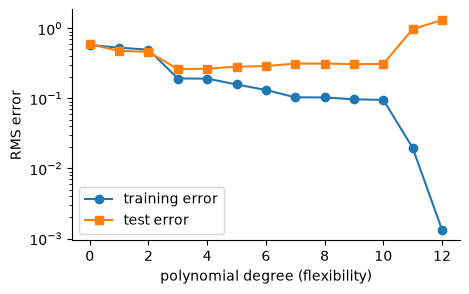

best degree on new data: 3 | training error keeps falling: [0.095 0.02  0.001]


In [5]:
rng = np.random.default_rng(3)
f = lambda x: np.sin(2 * x) + 0.3 * x
xt = np.sort(np.linspace(0.1, 2.9, 14) + rng.uniform(-0.08, 0.08, 14)); yt = f(xt) + 0.25 * rng.normal(size=14)
xn = rng.uniform(xt.min(), xt.max(), 300); yn = f(xn) + 0.25 * rng.normal(size=300)
train_err, test_err = [], []
for deg in range(13):
    p = np.polynomial.Polynomial.fit(xt, yt, deg)
    train_err.append(np.sqrt(np.mean((p(xt) - yt) ** 2))); test_err.append(np.sqrt(np.mean((p(xn) - yn) ** 2)))
plt.figure(figsize=(5, 3)); plt.plot(train_err, "o-", label="training error"); plt.plot(test_err, "s-", label="test error")
plt.yscale("log"); plt.xlabel("polynomial degree (flexibility)"); plt.ylabel("RMS error"); plt.legend(); plt.show()
print("best degree on new data:", int(np.argmin(test_err)), "| training error keeps falling:", np.round(train_err[-3:], 3))

## 5. Honest testing: split by packet, never by row

The 4 rows of a packet share the CCD's state at that moment. If some went to training and others to testing, a model could
recognize the packet from its reference features and look better than it is (**leakage**).

Below, the same model (boosted trees on the trace and reference features, predicting log λ) is scored twice:
* with folds that put each **row** anywhere;
* with folds that keep each **packet** together.

In [6]:
X, cols = data.make_inputs(df, ("theta", "trace", "ref"), drop_constant=False)
rows_as_groups = np.arange(len(df)).astype(str)            # every row its own group = a random split by row
m_row, s_row = grouped_cv(lambda: models.GBT(max_iter=150), X, Y, rows_as_groups)
m_pkt, s_pkt = grouped_cv(lambda: models.GBT(max_iter=150), X, Y, groups)
e_row = report("split by ROW (leaky)", Y, m_row, s_row)
e_pkt = report("split by PACKET (honest)", Y, m_pkt, s_pkt)
d = 100 * (e_pkt["lambda"]["error"] - e_row["lambda"]["error"])
print(f"\nλ: the row split looks {abs(d):.1f} percentage points {'better' if d > 0 else 'worse'} than the honest packet split.")

split by ROW (leaky)                     sigma_e:   7.6 % (cover 0.70)   lambda:  10.4 % (cover 0.71)   gain:   1.2 % (cover 0.70)
split by PACKET (honest)                 sigma_e:  14.1 % (cover 0.50)   lambda:  27.7 % (cover 0.33)   gain:   1.1 % (cover 0.69)

λ: the row split looks 17.3 percentage points better than the honest packet split.


In every notebook, scores come from **packet-grouped cross-validation**: the packets are split into 5 folds, and each fold is predicted by a
model trained on the other four (`tutorial_utils.grouped_cv`).

**Standardization.** Inputs come in volts, clock cycles and ADU. Most models first rescale each column to mean 0 and standard
deviation 1, using the **training rows only**. Every model in `src/ml/models.py` does this inside `fit`.

## 6. The probability you need

A **Gaussian** with mean μ and standard deviation σ puts 68 % of its values within μ ± σ and 95 % within μ ± 1.96σ. Our models predict a
mean **and** a standard deviation. A model is **calibrated** if its ±σ bars contain the truth 68 % of the time; this fraction is its
**coverage**.

**Why squared error?** If the noise is Gaussian with a fixed σ, the negative log-likelihood is
$\frac{1}{2\sigma^2}\sum_i (y_i-\mu_i)^2 + \text{const}$. Minimizing it *is* least squares.

In [7]:
rng = np.random.default_rng(0)
z = rng.normal(0, 1, 100_000)
print(f"fraction within ±1σ: {np.mean(abs(z) <= 1):.3f}   within ±1.96σ: {np.mean(abs(z) <= 1.96):.3f}")
# NLL and MSE pick the same line: scan the slope of the line in section 3
slopes = np.linspace(w_exact[0] - 0.2, w_exact[0] + 0.2, 201)
mse = [np.mean((y - s * x - w_exact[1]) ** 2) for s in slopes]
sig = 0.3
nll = [np.sum(0.5 * np.log(2 * np.pi * sig ** 2) + (y - s * x - w_exact[1]) ** 2 / (2 * sig ** 2)) for s in slopes]
print(f"slope minimizing MSE: {slopes[np.argmin(mse)]:.4f}   slope minimizing Gaussian NLL: {slopes[np.argmin(nll)]:.4f}")

fraction within ±1σ: 0.684   within ±1.96σ: 0.950
slope minimizing MSE: 0.5755   slope minimizing Gaussian NLL: 0.5755


## Summary

| Idea | Where it is used |
|---|---|
| one example = one amplifier's traces in a packet | every model |
| log targets: errors are relative | every report in these notebooks (errors in %) |
| loss + gradient descent | networks (03, 04, 12–14), GP hyperparameters (05) |
| over-fitting | choosing model size; regularization (01) |
| packet-grouped CV | every score |
| mean + standard deviation, coverage | GPs (05), ensembles (03), calibration (11) |

Next: **01 · Linear regression and Bayesian ridge**, the simplest model.